<a href="https://colab.research.google.com/github/EstelleYang111/MSSP607/blob/main/WeeklyModules/Week08Participation_Activity_Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo_path = "/content/MSSP607"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone",
         "https://github.com/EstelleYang111/MSSP607.git",
         repo_path],
        check=True
    )
else:
    subprocess.run(
        ["git", "-C", repo_path, "pull"],
        check=True
    )

os.chdir(repo_path)

df = pd.read_csv(
    "data/week08/InternetSales.csv",
    encoding="cp1252",
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [9]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

print("Earliest date:", df["OrderDate"].min())
print("Latest date:", df["OrderDate"].max())

display(df[["OrderDate", "EnglishProductName", "SalesAmount"]].head())

Earliest date: 2010-12-29 00:00:00
Latest date: 2014-01-28 00:00:00


,OrderDate,EnglishProductName,SalesAmount
0,2011-01-19,"Mountain-100 Silver, 38",3399.99
1,2013-01-18,"Mountain-200 Silver, 38",2319.99
2,2013-01-18,Fender Set - Mountain,21.98
3,2013-05-03,"Touring-1000 Blue, 46",2384.07
4,2013-05-03,Touring Tire,28.99


In [10]:
product_sales = (
    df.groupby("EnglishProductName")["SalesAmount"]
    .agg(["count", "sum", "mean", "median"])
    .sort_values(by="sum", ascending=False)
)

display(product_sales.head(10))

top_product = product_sales.index[0]
top_sales = product_sales.iloc[0]["sum"]

print("Product with the highest total sales:", top_product)
print(f"Total sales amount: {top_sales:,.2f}")


,count,sum,mean,median
EnglishProductName,,,,
"Mountain-200 Black, 46",620,1.373470e+06,2215.273465,2294.99
"Mountain-200 Black, 42",614,1.363142e+06,2220.101129,2294.99
"Mountain-200 Silver, 38",596,1.339463e+06,2247.420789,2319.99
"Mountain-200 Silver, 46",580,1.301100e+06,2243.276032,2319.99
"Mountain-200 Black, 38",582,1.294866e+06,2224.855913,2294.99
"Mountain-200 Silver, 42",560,1.257435e+06,2245.418880,2319.99
"Road-150 Red, 48",337,1.205877e+06,3578.270000,3578.27
"Road-150 Red, 62",336,1.202299e+06,3578.270000,3578.27
"Road-150 Red, 52",302,1.080638e+06,3578.270000,3578.27


Product with the highest total sales: Mountain-200 Black, 46
Total sales amount: 1,373,469.55


According to the aggregated statistics, the Mountain-200 Black 46 achieved the highest total sales amount of $1,373,469.55 in 620 sales records, with an average sales amount of approximately $2,215.27 per record. This indicates that it is the most outstanding individual product in the historical data set. However, the historical sales performance does not necessarily mean that it will bring the highest sales amount in the future.

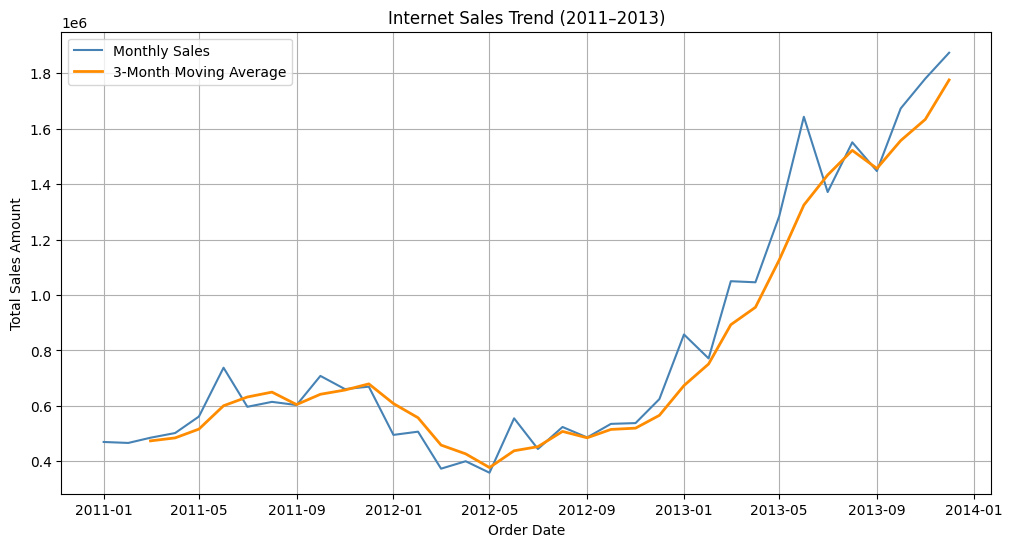

In [11]:
monthly_sales = (
    df.set_index("OrderDate")["SalesAmount"]
    .resample("MS")
    .sum()
)

monthly_sales = monthly_sales.loc["2011-01":"2013-12"]

moving_average = monthly_sales.rolling(window=3).mean()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Monthly Sales",
    color="steelblue"
)

plt.plot(
    moving_average.index,
    moving_average.values,
    label="3-Month Moving Average",
    color="darkorange",
    linewidth=2
)

plt.title("Internet Sales Trend (2011–2013)")
plt.xlabel("Order Date")
plt.ylabel("Total Sales Amount")
plt.legend()
plt.grid(True)
plt.show()

The monthly sales data show an overall upward trend from 2011 to 2013, despite some fluctuations. Sales declined during the first half of 2012 but increased substantially throughout 2013. The three-month moving average helps smooth short-term fluctuations and highlights the general growth in sales.

In [12]:
from sklearn.linear_model import LinearRegression

sales_values = monthly_sales.values

X = np.arange(len(monthly_sales)).reshape(-1, 1)
y = sales_values

model = LinearRegression()
model.fit(X, y)

future_X = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 60
).reshape(-1, 1)

future_dates = pd.date_range(
    start="2014-01-01",
    periods=60,
    freq="MS"
)

forecast_values = model.predict(future_X)

forecast = pd.DataFrame({
    "Date": future_dates,
    "PredictedSales": forecast_values
})

forecast["Year"] = forecast["Date"].dt.year

annual_forecast = (
    forecast.groupby("Year")["PredictedSales"]
    .sum()
)

print("Forecasted Annual Sales:")
display(annual_forecast.round(2))


Forecasted Annual Sales:


,PredictedSales
Year,
2014,19373754.06
2015,24182370.85
2016,28990987.64
2017,33799604.43
2018,38608221.22


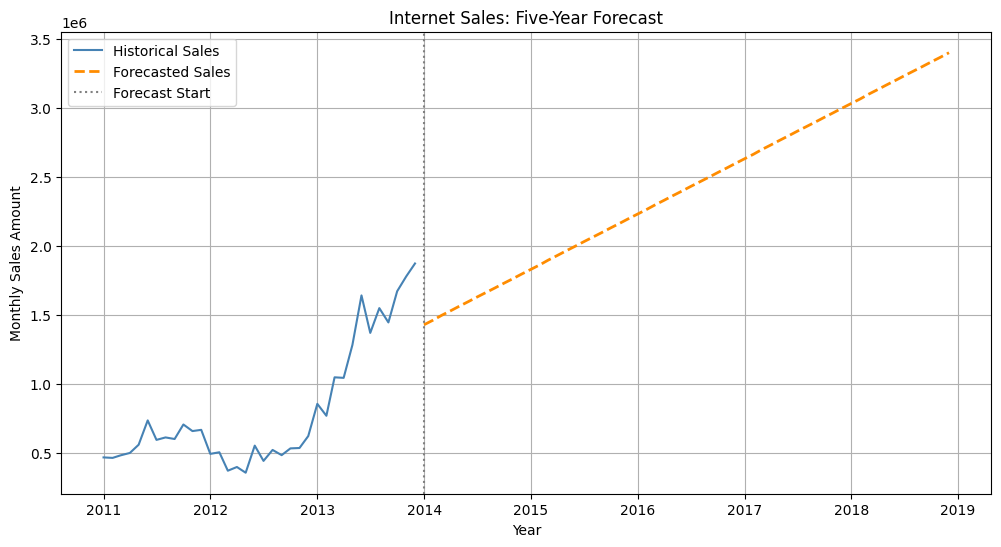

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Historical Sales",
    color="steelblue"
)

plt.plot(
    forecast["Date"],
    forecast["PredictedSales"],
    label="Forecasted Sales",
    color="darkorange",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    x=pd.Timestamp("2014-01-01"),
    color="gray",
    linestyle=":",
    label="Forecast Start"
)

plt.title("Internet Sales: Five-Year Forecast")
plt.xlabel("Year")
plt.ylabel("Monthly Sales Amount")
plt.legend()
plt.grid(True)
plt.show()

A linear regression model was used to forecast Internet Sales for the next five years (2014–2018), based on monthly sales data from 2011 to 2013. The model predicts that annual sales will increase from approximately 19.37 million in 2014 to 38.61 million in 2018, with a total forecast of approximately 144.96 million over five years. These results reflect an extrapolation of the historical trend. Because the model is based on only three complete years of data and does not account for seasonality, the estimates should be interpreted with caution.